<a href="https://colab.research.google.com/github/unknxwNS/Ihopeitworks/blob/main/%D0%9C%D1%96%D1%85%D0%B0%D0%BB%D1%8C%D0%BE%D0%B2_%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Міхальов Андрій  
**Група:** ФІТ 4-10
 **Дата:** 25.11

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# NumPy
import numpy as np

# Matplotlib
import matplotlib.pyplot as plt

# Оцінювання якості класифікації
from sklearn.metrics import classification_report

# Callback-функції
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.4.6


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
# Завантаження Fashion MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Назви класів
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

# Виведення форм масивів
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

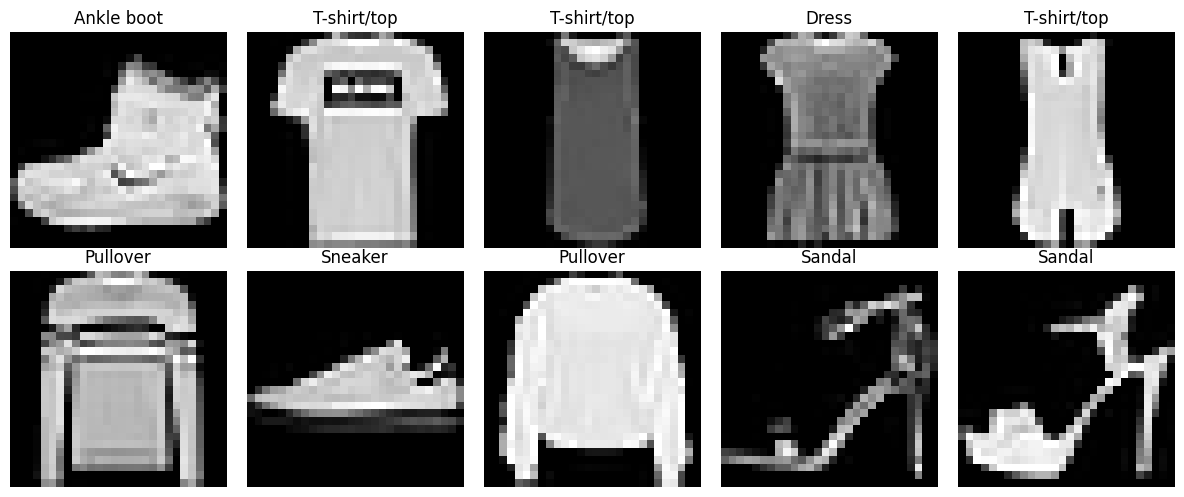

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
# Створення сітки 2×5
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Відображення зображення
    plt.imshow(x_train[i], cmap='gray')

    # Підпис класу
    plt.title(class_names[y_train[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
# Нормалізація навчальних і тестових даних
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Перевірка діапазонів значень
print("Діапазон x_train:", x_train.min(), "-", x_train.max())
print("Діапазон x_test:", x_test.min(), "-", x_test.max())

Діапазон x_train: 0.0 - 1.0
Діапазон x_test: 0.0 - 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
# Створення послідовної нейронної мережі
model = keras.Sequential([
    # Перетворення зображення 28×28 у вектор
    layers.Flatten(input_shape=(28, 28)),

    # Повнозв'язні шари з ReLU
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),

    # Вихідний шар для 10 класів
    layers.Dense(10, activation='softmax')
])

# Компіляція моделі
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Перегляд архітектури моделі
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
# Налаштування callback-функцій
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        'best_model.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )
]

# Навчання моделі
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7729 - loss: 0.6361 - val_accuracy: 0.8506 - val_loss: 0.4133 - learning_rate: 0.0010
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8421 - loss: 0.4379 - val_accuracy: 0.8652 - val_loss: 0.3783 - learning_rate: 0.0010
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8551 - loss: 0.3959 - val_accuracy: 0.8702 - val_loss: 0.3606 - learning_rate: 0.0010
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8634 - loss: 0.3734 - val_accuracy: 0.8700 - val_loss: 0.3560 - learning_rate: 0.0010
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8706 - loss: 0.3529 - val_accuracy: 0.8766 - val_loss: 0.3400 - learning_rate: 0.0010
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8764 - loss: 0.3401 - val_accuracy: 0.8822 - val_loss: 0.3260 - learning_rate: 0.0010
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8802 - loss: 0.3

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
# Підсумок архітектури моделі
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
# Збереження найкращої навченої моделі
model.save('fashion_mnist_model.keras')

print("Модель успішно збережена!")

Модель успішно збережена!


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

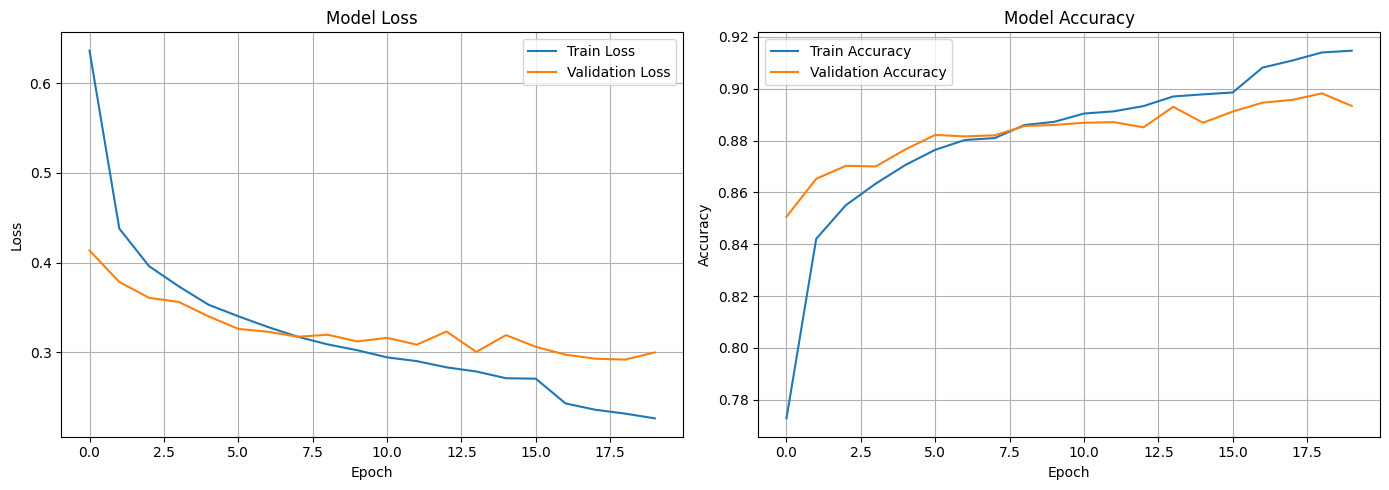

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
# Створення області для двох графіків
plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
# Оцінювання моделі на тестовій вибірці
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Отримання прогнозів моделі
y_pred_prob = model.predict(x_test)

# Перетворення ймовірностей у номери класів
y_pred = np.argmax(y_pred_prob, axis=1)

# Формування звіту класифікації
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names
)

print("\nClassification Report:")
print(report)

Test Loss: 0.3187
Test Accuracy: 0.8907
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.82      0.88      0.85      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.82      0.81      1000
       Dress       0.89      0.90      0.89      1000
        Coat       0.81      0.81      0.81      1000
      Sandal       0.99      0.96      0.97      1000
       Shirt       0.73      0.68      0.70      1000
     Sneaker       0.94      0.97      0.96      1000
         Bag       0.99      0.96      0.97      1000
  Ankle boot       0.96      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
errors_by_class = cm.sum(axis=1) - np.diag(cm)

for i, errors in enumerate(errors_by_class):
    print(f"{class_names[i]}: {errors} помилок")

T-shirt/top: 124 помилок
Trouser: 30 помилок
Pullover: 180 помилок
Dress: 103 помилок
Coat: 190 помилок
Sandal: 44 помилок
Shirt: 320 помилок
Sneaker: 27 помилок
Bag: 36 помилок
Ankle boot: 39 помилок


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

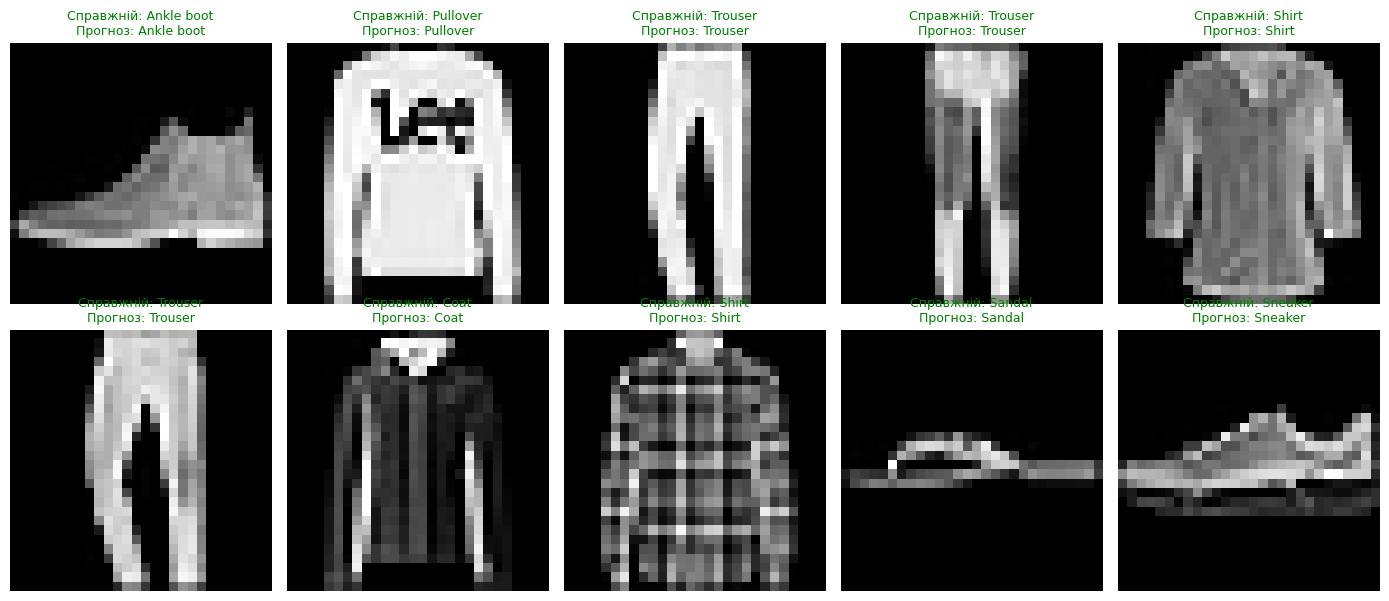

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
# Візуалізація 10 тестових зображень
plt.figure(figsize=(14, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Відображення зображення
    plt.imshow(x_test[i], cmap='gray')

    # Справжній та прогнозований класи
    true_label = class_names[y_test[i]]
    predicted_label = class_names[y_pred[i]]

    # Колір підпису залежить від правильності прогнозу
    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f"Справжній: {true_label}\nПрогноз: {predicted_label}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
У результаті тестування модель досягла точності **89,07%**. Найбільше помилок було під час розпізнавання сорочок (320), пальт (190) та светрів (180). Це пов'язано зі схожістю зовнішнього вигляду цих категорій одягу. Найкраще модель розпізнавала кросівки, штани та сумки. Вимогу щодо мінімальної точності **виконано, якщо встановлений поріг не перевищує 89,07%**.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch

from tensorflow import keras
from tensorflow.keras import layers

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
from sklearn.model_selection import train_test_split

# Розділення навчальної вибірки
x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Тестова вибірка залишається окремою
x_test_final = x_test
y_test_final = y_test

print("Тренувальна вибірка:", x_train_tuner.shape)
print("Валідаційна вибірка:", x_val_tuner.shape)
print("Тестова вибірка:", x_test_final.shape)

Тренувальна вибірка: (48000, 28, 28)
Валідаційна вибірка: (12000, 28, 28)
Тестова вибірка: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()

    # Вхідний шар
    model.add(layers.Flatten(input_shape=(28, 28)))

    # Кількість прихованих шарів: від 1 до 3
    num_layers = hp.Int('num_layers', min_value=1, max_value=3)

    for i in range(num_layers):
        # Кількість нейронів: від 32 до 512 з кроком 32
        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32
        )

        # Dropout
        dropout_rate = hp.Float(
            f'dropout_{i}',
            min_value=0.2,
            max_value=0.5,
            step=0.1
        )

        # L2-регуляризація
        l2_value = hp.Choice(
            f'l2_{i}',
            values=[0.0001, 0.001, 0.01]
        )

        model.add(layers.Dense(
            units,
            activation='relu',
            kernel_regularizer=keras.regularizers.l2(l2_value)
        ))

        model.add(layers.Dropout(dropout_rate))

    # Вихідний шар для 10 класів
    model.add(layers.Dense(10, activation='softmax'))

    # Швидкість навчання
    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='fashion_mnist_tuning',
    project_name='random_search'
)

# Перегляд простору гіперпараметрів
tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.2, 'conditions': [], 'min_value': 0.2, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2_0 (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
# Callbacks для пошуку
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )
]

# Запуск пошуку гіперпараметрів
tuner.search(
    x_train_tuner,
    y_train_tuner,
    epochs=20,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=callbacks,
    verbose=1
)

# Отримання найкращих гіперпараметрів
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")
print("Кількість прихованих шарів:", best_hp.get('num_layers'))
print("Швидкість навчання:", best_hp.get('learning_rate'))

for i in range(best_hp.get('num_layers')):
    print(f"Шар {i + 1}:")
    print("Нейрони:", best_hp.get(f'units_{i}'))
    print("Dropout:", best_hp.get(f'dropout_{i}'))
    print("L2:", best_hp.get(f'l2_{i}'))

# Отримання найкращої моделі
best_model = tuner.get_best_models(num_models=1)[0]

print("\nСтруктура найкращої моделі:")
best_model.summary()

# Повторне навчання обраної конфігурації
final_model = build_model(best_hp)

history_tuned = final_model.fit(
    x_train_tuner,
    y_train_tuner,
    epochs=20,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=callbacks,
    verbose=1
)

Trial 3 Complete [00h 01m 54s]
val_accuracy: 0.8375833630561829

Best val_accuracy So Far: 0.8821666836738586
Total elapsed time: 00h 04m 40s
Найкращі гіперпараметри:
Кількість прихованих шарів: 2
Швидкість навчання: 0.0001
Шар 1:
Нейрони: 320
Dropout: 0.2
L2: 0.001
Шар 2:
Нейрони: 96
Dropout: 0.4
L2: 0.001

Структура найкращої моделі:


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 320)            │       251,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 96)             │        30,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,986 (1.08 MB)

 Trainable params: 282,986 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6330 - loss: 1.6767 - val_accuracy: 0.8049 - val_loss: 1.1494 - learning_rate: 1.0000e-04
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.7721 - loss: 1.1881 - val_accuracy: 0.8278 - val_loss: 0.9936 - learning_rate: 1.0000e-04
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8010 - loss: 1.0487 - val_accuracy: 0.8410 - val_loss: 0.9055 - learning_rate: 1.0000e-04
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8187 - loss: 0.9606 - val_accuracy: 0.8510 - val_loss: 0.8461 - learning_rate: 1.0000e-04
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8285 - loss: 0.9007 - val_accuracy: 0.8552 - val_loss: 0.8060 - learning_rate: 1.0000e-04
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8382 - loss: 0.8522 - val_accuracy: 0.8575 - val_loss: 0.7679 - learning_rate: 1.0000e-04
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - acc

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test Loss: 0.5539
Test Accuracy: 0.8684


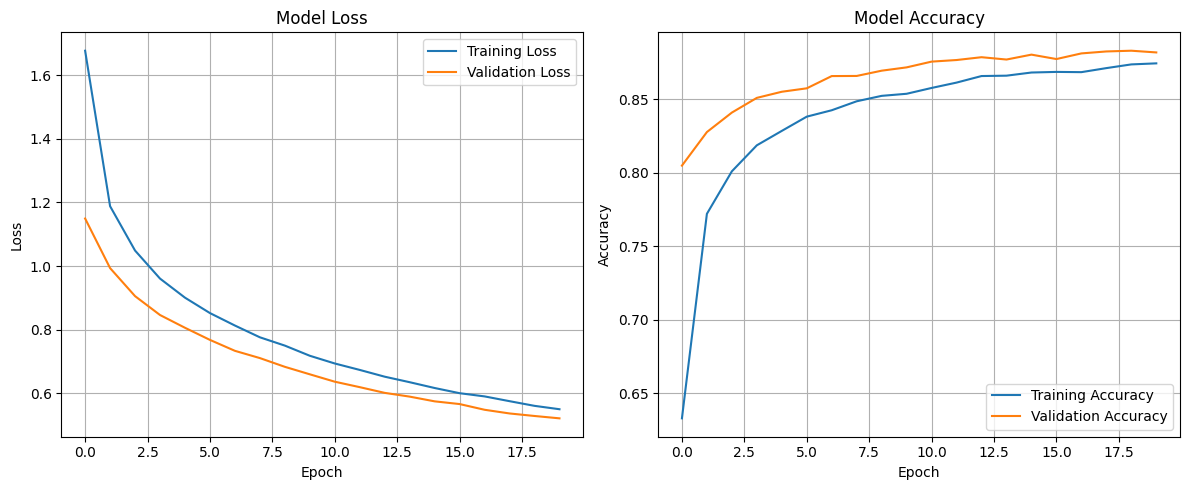

In [18]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
# Фінальне оцінювання на тестовій вибірці
test_loss, test_accuracy = final_model.evaluate(
    x_test_final,
    y_test_final,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Графік функції втрат
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['loss'], label='Training Loss')
plt.plot(history_tuned.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['accuracy'], label='Training Accuracy')
plt.plot(history_tuned.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
print("НАЙКРАЩІ ГІПЕРПАРАМЕТРИ")
print("Кількість шарів:", best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(f"Шар {i + 1}: {best_hp.get(f'units_{i}')} нейронів")

print("Learning rate:", best_hp.get('learning_rate'))

print("\nРЕЗУЛЬТАТИ")
print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)
print("Кількість епох:", len(history_tuned.history['loss']))

НАЙКРАЩІ ГІПЕРПАРАМЕТРИ
Кількість шарів: 2
Шар 1: 320 нейронів
Шар 2: 96 нейронів
Learning rate: 0.0001

РЕЗУЛЬТАТИ
Test Accuracy: 0.868399977684021
Test Loss: 0.553871214389801
Кількість епох: 20


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |2| 2|
| Кількість нейронів | 256, 128	 | 320, 96 |
| Швидкість навчання | 0,001 | 0,0001 |
| Точність на тестовій вибірці (accuracy) | 89,07% | 86,84% |
| Втрати на тестовій вибірці (loss) | 0,3187 | 0,5539 |
| Кількість епох навчання | 20 | 20 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?


-
1. Так, початкова модель досягла точності 89,07%, а налаштована — 86,84%.
Обидві перевищили мінімальну вимогу 0,87 лише перша.

2. Оптимізація не покращила точність на тестовій вибірці: вона знизилася на 2,23 відсоткового пункта.

3. Найкращими під час пошуку виявилися 2 приховані шари з 320 та 96 нейронами і швидкість навчання 0,0001. Результат може відрізнятися через випадковість навчання та обмежену кількість спроб пошуку.

4. Найскладніше класифікувати сорочки, пальта та светри через схожість їхнього зовнішнього вигляду.

**Власні висновки:**  
Тепер можемо заповнити таблицю повністю, крім кількості епох початкової моделі — її потрібно взяти з першого навчання.

### **1. Таблиця порівняння моделей**

| Показник                     | Модель із завдання 1            | Модель після Keras Tuner |
| ---------------------------- | ------------------------------- | ------------------------ |
| Кількість прихованих шарів   | 2                               | 2                        |
| Кількість нейронів           | 256, 128                        | 320, 96                  |
| Швидкість навчання           | 0,001                           | 0,0001                   |
| Точність на тестовій вибірці | 89,07%                          | 86,84%                   |
| Втрати на тестовій вибірці   | 0,3187                          | 0,5539                   |
| Кількість епох навчання      | 20 (якщо всі епохи завершилися) | 20                       |

### **2. Відповіді на питання**

1. Так, початкова модель досягла точності 89,07%, а налаштована — 86,84%. Обидві перевищили мінімальну вимогу 0,87 лише перша.
2. Оптимізація не покращила точність на тестовій вибірці: вона знизилася на 2,23 відсоткового пункта.
3. Найкращими під час пошуку виявилися 2 приховані шари з 320 та 96 нейронами і швидкість навчання 0,0001. Результат може відрізнятися через випадковість навчання та обмежену кількість спроб пошуку.
4. Найскладніше класифікувати сорочки, пальта та светри через схожість їхнього зовнішнього вигляду.

### **3. Власний висновок (5 речень)**

У ході роботи було порівняно початкову нейронну мережу та модель після автоматичного налаштування гіперпараметрів. Початкова модель показала кращу точність — 89,07%, тоді як налаштована досягла 86,84%. Отже, автоматична оптимізація не покращила результат у цьому експерименті, хоча дозволила підібрати іншу конфігурацію мережі. Найбільше труднощів обидві моделі можуть мати з розпізнаванням візуально схожих категорій одягу. Мінімальну вимогу точності 0,87 виконала початкова модель, а результат налаштованої моделі виявився трохи нижчим за потрібний поріг.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.